# Joint controlled processes

**A forecast for several series can get every series right and still get the risk wrong, if it misses how they move together.** To test for that, you need series whose links you set yourself.

A possible future of several series is a whole table: every target at every horizon. This chapter extends [chapter 14](14_controlled_processes.ipynb)'s four recipes to several targets with declared links: correlated everyday shocks, jumps that hit every series at the same moments, one hidden regime that drives them all, and CCC-GARCH, where each series has its own calm and stormy periods while their shocks stay correlated. For each recipe it builds the joint answer key: the mean and covariance of every target at every horizon, and possible futures that keep the targets paired.

You will see two series jumping together, one link seen in returns and in log prices, how precise an estimated link is, a link that moves with the hidden regime, links that survive zero correlation, and which parts of each answer key are exact.

**Development notebook.** Library cells are collapsed; expand them to edit the code, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp joint_processes

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from timegym import Scenario
from timegym.scenarios import scenario_label

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
pd.set_option('display.max_colwidth', None)
BLUE = '#0000CC'


def draw_case(ax, case, title, target=0, last=48):
    # One series: the end of its history, what actually happened, and the answer key with its 80% range.
    history = case.task.context.iloc[-last:, target]
    low, high = case.reference.quantile((.1, .9))[:, target].T
    ax.scatter(history.index, history, s=6, color='0.65', zorder=3, label='History')
    ax.scatter(case.observed.index, case.observed.iloc[:, target], s=8, color='0.3', zorder=3,
               label='What actually happened')
    ax.fill_between(case.reference.index, low, high, color='0.88', linewidth=0, zorder=1,
                    label='Answer key, 80% range')
    ax.plot(case.reference.index, case.reference.mean[:, target], color='0.2', linewidth=0.9, zorder=2,
            label='Answer key (mean)')
    ax.axvline(case.task.future_index[0] - 0.5, color=BLUE, linestyle='--', linewidth=0.8)
    ax.set_title(title, fontsize=10)


def correlation(reference):
    # The answer key's covariance as correlations: one row and column per (step, series).
    spread = np.sqrt(np.diag(reference.covariance))
    return reference.covariance / np.outer(spread, spread)

## How the series are linked

Settings work as in chapter 14: one number applies to every series, and a list gives one value per series. The links are always declared, never implied:

- `correlation` sets how strongly the everyday shocks move together, as one number or a full matrix.
- **One jump clock.** In the composed and Merton recipes, jumps arrive at the same moments in every series; `jump_correlation` sets how alike their sizes are.
- **One hidden regime.** In the regime recipe a single hidden chain drives every series, and `regime_correlation` can give each regime its own correlation matrix. The answer key works out the regime from all the series together.
- **CCC-GARCH.** Each series has its own GARCH volatility, and their shocks keep one constant correlation.

The model never sees the settings or the hidden regime. Zero `correlation` does not make the series independent when they share a jump clock or a regime; a demonstration near the end shows it.

In [3]:
#| export joint_processes
from __future__ import annotations
import numpy as np
from scipy.special import logsumexp
from scipy.stats import poisson
from timegym._internal import _deprecated
from timegym._process_common import (
    _PROCESS_REGISTRY, _CHANGE_FIELDS, _TAIL_TOLERANCE,
    _exp, _factor, _emission_law, _state_parameters, _streams,
    _to_values, _observed_returns, _transform_samples, _build_case,
)


### One step of every series at once

`_draw_emission` draws one step for all the series: correlated everyday shocks, one jump count shared by every series, and correlated jump sizes.

In [4]:
#| export joint_processes
def _draw_emission(rng, n, law):
    d = len(law['mean'])
    counts = rng['jump_counts'].poisson(law['intensity'], size=n)
    return (law['drift']+rng['diffusion'].standard_normal((n, d))@law['diffusion_factor'].T
            + counts[:, None]*law['jump_mean']
            + np.sqrt(counts)[:, None]*(rng['jump_sizes'].standard_normal((n, d))@law['jump_factor'].T))

### Every target at every horizon, in one covariance

The answer key's covariance has one row and one column for each step and series, ordered step by step: (step 1, `y0`), (step 1, `y1`), (step 2, `y0`), and so on. Possible futures come as an array of draws × steps × series in the same order, so each draw keeps its series paired. Quantiles are per series and per step: they are not a region that a whole path, or both series together, stays inside.

In [5]:
#| export joint_processes
def _blocks_to_covariance(blocks, *, cumulative=False):
    """Blocks use (horizon, target, horizon, target), matching C-order samples."""
    if cumulative:
        blocks = blocks.cumsum(axis=0).cumsum(axis=2)
    h, d = blocks.shape[:2]
    return blocks.reshape(h*d, h*d)

## Composed series: one recipe per series, linked shocks

Each series gets its own line, cycle and noise. A change point applies at the same step to every series, with new values per series. With `residual='random_walk'`, shocks accumulate in every series, and the shared jump clock can move all their levels at once.

In [6]:
#| export joint_processes
def _joint_composite(p, length, horizon, d, seed):
    t = np.arange(length+horizon)[:, None]
    schedule = {}
    for key in _CHANGE_FIELDS:
        a = np.broadcast_to(p[key], (len(t), d)).copy()
        if p['change_point'] is not None and key in p['changes']:
            a[np.arange(len(t)) >= p['change_point']] = p['changes'][key]
        schedule[key] = a
    signal = (schedule['intercept']+schedule['slope']*t+schedule['amplitude']
              *np.sin(2*np.pi*t/schedule['period']+schedule['phase']))
    corr = np.asarray(p['correlation']); factor = _factor(corr)
    jm = np.asarray(p['jump_mean']); js = np.asarray(p['jump_sigma'])
    jump_cov = np.outer(js, js)*p['jump_correlation']; jump_factor = _factor(jump_cov)
    rng = _streams(seed, joint=True)
    def innovation(streams, n, sigma):
        shock = (streams['diffusion'].standard_normal((n, d))@factor.T)*sigma
        if p['jump_rate']:
            counts = streams['jump_counts'].poisson(p['jump_rate'], size=n)
            shock += counts[:, None]*jm+np.sqrt(counts)[:, None]*(streams['jump_sizes'].standard_normal((n, d))@jump_factor.T)
        return shock
    residual = np.empty_like(signal)
    for i in range(len(t)):
        shock = innovation(rng, 1, schedule['sigma'][i])[0]
        if p['residual'] == 'random_walk' and i == 0:
            residual[i] = 0.
        else:
            residual[i] = shock
            if p['residual'] == 'random_walk':
                residual[i] += residual[i-1]
    values = signal+residual
    last_residual = values[length-1]-signal[length-1]
    increments = np.array([np.outer(s, s)*corr+p['jump_rate']*(jump_cov+np.outer(jm, jm))
                           for s in schedule['sigma'][length:]])
    mean = signal[length:].copy()
    blocks = np.zeros((horizon, d, horizon, d))
    for h in range(horizon):
        blocks[h, :, h, :] = increments[h]
    cumulative = p['residual'] == 'random_walk'
    if cumulative:
        mean += last_residual+np.arange(1, horizon+1)[:, None]*p['jump_rate']*jm
    def sampler(n, sample_seed):
        streams = _streams(sample_seed, role=1, joint=True)
        out = np.empty((n, horizon, d)); previous = np.broadcast_to(last_residual, (n, d)).copy()
        for h in range(horizon):
            shocks = innovation(streams, n, schedule['sigma'][length+h])
            previous = previous+shocks if cumulative else shocks
            out[:, h] = signal[length+h]+previous
        return out
    info = dict(residual=p['residual'], future_parameter_schedule_known=True,
                schedule_convention='absolute_time_intercept_plus_slope_t',
                residual_level_from_observed_history=last_residual.tolist() if cumulative else None,
                dependence='correlated_innovations_and_shared_Poisson_jump_clock')
    return values, mean, _blocks_to_covariance(blocks, cumulative=cumulative), info, sampler if p['jump_rate'] else None, {}

### Two recipes, one jump clock

`y0` is a cycle around 10 and `y1` a rising line. Their everyday shocks are correlated at 0.7 and accumulate, and about every 33 steps a jump hits both, mostly downward. To find the jumps, we generate the same pair again with `jump_rate=0`: at a fixed seed the everyday shocks are the same, so the two versions differ only where a jump landed.

Jumps landed on both series at steps 104, 129.


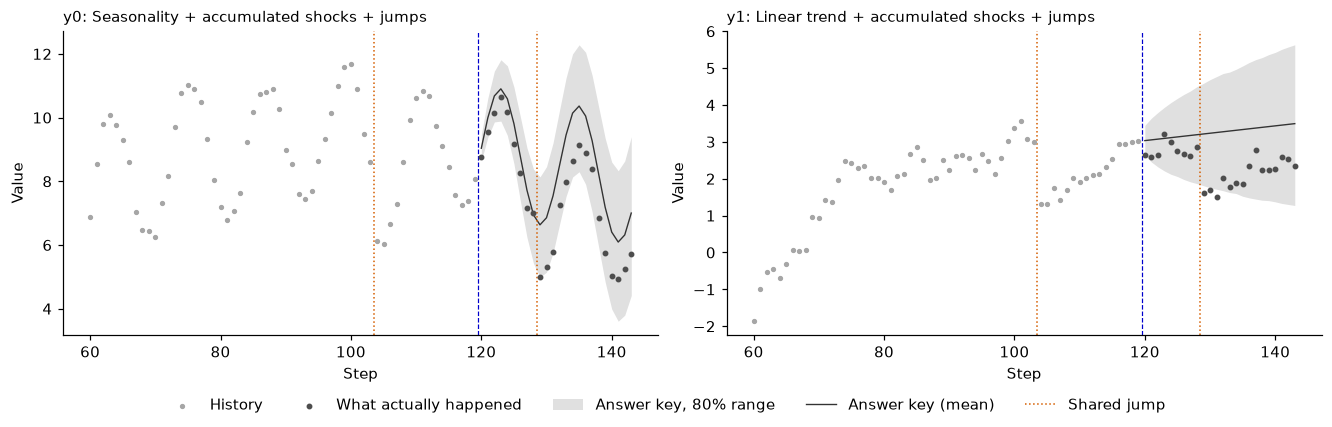

In [7]:
two_recipes = {'intercept': [10., 0.], 'slope': [0., .05], 'amplitude': [2., 0.], 'sigma': .3,
               'residual': 'random_walk', 'correlation': .7,
               'jump_rate': .03, 'jump_mean': [-1.5, -1.], 'jump_sigma': .3, 'jump_correlation': .8}
pair = Scenario('composite', context_length=120, horizon=24, parameters=two_recipes, n_targets=2, seed=4)
case = pair.generate()
no_jumps = Scenario('composite', context_length=120, horizon=24, n_targets=2, seed=4,
                    parameters={**two_recipes, 'jump_rate': 0.}).generate()
gap = np.vstack([case.task.context, case.observed]) - np.vstack([no_jumps.task.context, no_jumps.observed])
landed = np.abs(np.diff(gap, axis=0)) > 1e-9                  # where the gap moves, series by series
np.testing.assert_array_equal(landed[:, 0], landed[:, 1])     # every jump hits both series at the same step
jump_steps = np.flatnonzero(landed[:, 0]) + 1
print(f'Jumps landed on both series at steps {", ".join(map(str, jump_steps))}.')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
for target, ax in enumerate(axes):
    name = scenario_label('composite', case.manifest['parameters'], target_index=target)
    draw_case(ax, case, f'y{target}: {name}', target=target, last=60)
    for k, step in enumerate(jump_steps[jump_steps >= 60]):
        ax.axvline(step - .5, color='#D55E00', linestyle=':', linewidth=1,
                   label='Shared jump' if k == 0 else None)
    ax.set(xlabel='Step', ylabel='Value')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=5)
plt.show()

Jumps landed at steps 104 and 129, on both series at once, as the check in the cell confirms. The second lands nine steps into the forecast, and both series drop together. The answer key can't know when the next jump will come, only that one might: its range widens with the horizon as accumulated shocks and possible jumps add up.

## Merton jumps on one shared clock

Each series is a Merton price from chapter 14, with its own drift, volatility and jump sizes. Their everyday moves are correlated, and one jump clock makes them jump together. The answer key's mean and covariance are exact in returns, log prices and prices. Its possible futures are simulated from the true recipe, except in the one case where the law is a bell curve: no jumps, and returns or log prices.

In [8]:
#| export joint_processes
def _joint_merton(p, length, horizon, d, seed):
    law = _emission_law(p); rng = _streams(seed, joint=True)
    count = length+horizon-(p['output'] != 'log_return')
    returns = np.array([_draw_emission(rng, 1, law)[0] for _ in range(count)])
    values = _to_values(returns, p); last = values[length-1]
    blocks = np.zeros((horizon, d, horizon, d))
    mean = np.broadcast_to(law['mean'], (horizon, d)).copy()
    for h in range(horizon):
        blocks[h, :, h, :] = law['covariance']
    if p['output'] == 'price':
        mean = _exp(np.log(last)+np.arange(1, horizon+1)[:, None]*np.array(p['mu'])*p['dt'], 'Joint price mean')
        for h in range(horizon):
            for j in range(horizon):
                blocks[h, :, j, :] = np.outer(mean[h], mean[j])*np.expm1(min(h+1, j+1)*law['spread'])
    elif p['output'] == 'log_price':
        mean = last+mean.cumsum(axis=0)
    covariance = _blocks_to_covariance(blocks, cumulative=p['output'] == 'log_price')
    def sampler(n, sample_seed):
        streams = _streams(sample_seed, role=1, joint=True)
        draws = np.stack([_draw_emission(streams, n, law) for _ in range(horizon)], axis=1)
        return _transform_samples(draws, p, last)
    info = dict(output_units=p['output'], drift_convention='physical_expected_proportional_price_growth',
                dependence='correlated_diffusion_and_shared_Poisson_jump_clock')
    gaussian = p['jump_rate'] == 0 and p['output'] != 'price'
    return values, mean, covariance, info, None if gaussian else sampler, {}

### The same link in returns and in log prices

Two jumping series, shocks correlated at 0.6 and jump sizes at 0.8, forecast four steps ahead: once as returns and once as log prices. Each heat map shows the answer key's correlation between every pair of step and series, eight rows and eight columns.

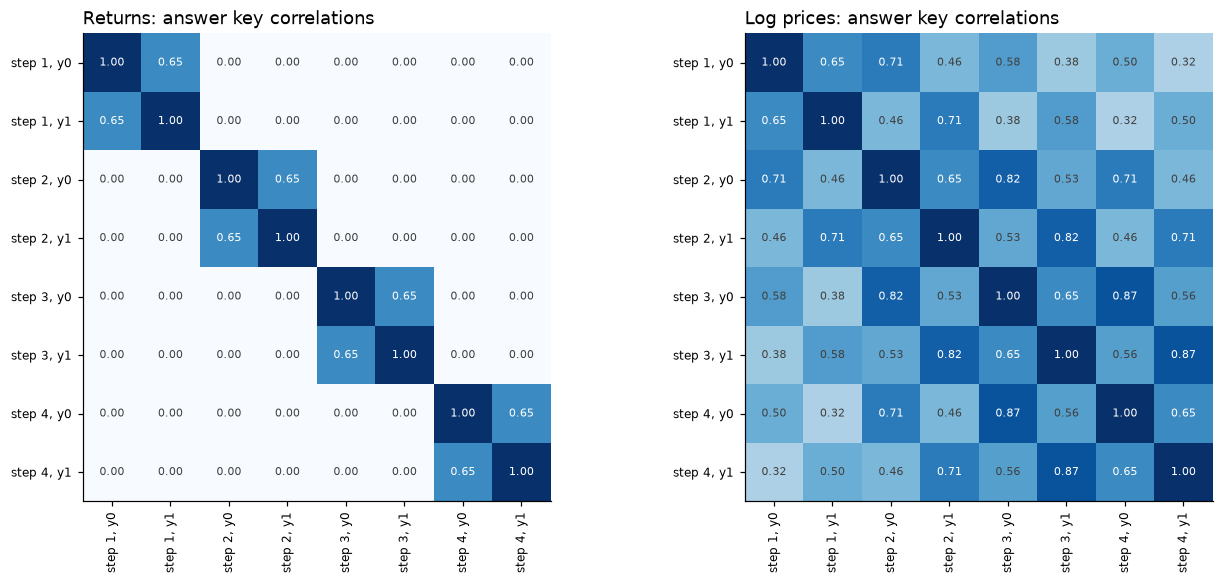

In [9]:
linked = {'correlation': .6, 'jump_correlation': .8, 'jump_mean': [-.08, -.15], 'jump_sigma': [.08, .12]}
views = {unit: Scenario('merton_jump_diffusion', horizon=4, n_targets=2,
                        parameters={**linked, 'output': unit}).generate(seed=23)
         for unit in ('log_return', 'log_price')}
draws = views['log_return'].reference.sample(128, seed=91)
assert draws.shape == (128, 4, 2)  # 128 possible futures, each 4 steps × 2 series, kept together

in_returns, in_log_prices = (correlation(views[unit].reference) for unit in ('log_return', 'log_price'))
other_steps = ~np.kron(np.eye(4, dtype=bool), np.ones((2, 2), dtype=bool))
assert np.all(in_returns[other_steps] == 0)  # returns: different steps are unlinked
assert np.all(in_log_prices > 0)             # log prices: every step and series is linked

labels = [f'step {step}, y{target}' for step in range(1, 5) for target in range(2)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), layout='constrained')
for ax, matrix, title in zip(axes, (in_returns, in_log_prices), ('Returns', 'Log prices')):
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=1)
    for (row, column), value in np.ndenumerate(matrix):
        ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=7.5,
                color='white' if value > .6 else '0.25')
    ax.set_xticks(range(8), labels, rotation=90, fontsize=8)
    ax.set_yticks(range(8), labels, fontsize=8)
    ax.set_title(f'{title}: answer key correlations')
plt.show()

In returns, the only links are between the two series at the same step: 0.65, a little above the shocks' 0.6, because the shared jumps add a link of their own. Different steps are unlinked, because each step's return is new. In log prices everything is linked: a log price carries every earlier return, so `y0` at step 1 and at step 4 are correlated at 0.50, and even `y0` at step 1 and `y1` at step 4 at 0.32. A check that looks at one series, or one step, at a time sees none of this.

## CCC-GARCH: separate storms, linked shocks

Each series runs its own GARCH volatility (chapter 14), and their shocks keep one constant correlation (CCC: constant conditional correlation). Possible futures are simulated exactly, and the means, each series' variance and the one-step link between series are exact formulas. Further ahead the link depends on how the two volatilities wander together, which has no general formula, so TimeGym estimates it once from `moment_samples` simulated paths (16,384 by default) with its own `moment_seed`, holds it fixed and labels it.

In [10]:
#| export joint_processes
def _joint_garch(p, length, horizon, d, seed):
    mu, omega, alpha, beta, initial = [np.asarray(p[key]) for key in ('mu', 'omega', 'alpha', 'beta', 'initial_variance')]
    corr = np.asarray(p['correlation']); factor = _factor(corr)
    count = length+horizon-(p['output'] != 'log_return')
    rng = _streams(seed, joint=True)['diffusion']; variance = initial.copy()
    returns = np.empty((count, d))
    for t in range(count):
        shock = np.sqrt(variance)*(rng.standard_normal(d)@factor.T)
        returns[t] = mu+shock
        variance = omega+alpha*shock**2+beta*variance
    values = _to_values(returns, p); last = values[length-1]
    next_variance = initial.copy()
    for value in _observed_returns(values, p, length):
        next_variance = omega+alpha*(value-mu)**2+beta*next_variance
    expected = np.empty((horizon, d)); expected[0] = next_variance
    for h in range(1, horizon):
        expected[h] = omega+(alpha+beta)*expected[h-1]
    def simulate(n, sample_seed, role=1, moments=False):
        streams = _streams(sample_seed, role=role, joint=True); rng = streams['diffusion']
        v = np.broadcast_to(next_variance, (n, d)).copy()
        out = np.empty((n, horizon, d)) if not moments else np.empty((horizon, d, d))
        for h in range(horizon):
            roots = np.sqrt(v)
            if moments:
                # Average conditional covariance, not noisy sample return covariance.
                q = (roots.T@roots/n)*corr
                correction = np.sqrt(expected[h]/np.diag(q))
                out[h] = q*np.outer(correction, correction)
                np.fill_diagonal(out[h], expected[h])
            shock = roots*(rng.standard_normal((n, d))@factor.T)
            if not moments:
                out[:, h] = mu+shock
            v = omega+alpha*shock**2+beta*v
        return out
    # The first-step covariance, diagonal-correlation case and deterministic
    # variance paths are analytic. Otherwise E[sqrt(v_i v_j)] needs integration.
    numerical = horizon > 1 and np.any(alpha > 0) and np.any(corr != np.eye(d))
    if numerical:
        q = simulate(p['moment_samples'], p['moment_seed'], role=2, moments=True)
    else:
        q = np.array([np.outer(np.sqrt(v), np.sqrt(v))*corr for v in expected])
    blocks = np.zeros((horizon, d, horizon, d))
    for h in range(horizon):
        blocks[h, :, h, :] = q[h]
    mean = np.broadcast_to(mu, (horizon, d)).copy()
    if p['output'] == 'log_price':
        mean = last+mean.cumsum(axis=0)
    def sampler(n, sample_seed):
        return _transform_samples(simulate(n, sample_seed), p, last)
    info = dict(output_units=p['output'], dependence='constant_conditional_correlation_GARCH',
                next_variance_from_observed_history=next_variance.tolist(),
                moment_random_stream='independent_of_observations_and_reference_samples')
    capabilities = dict(moments_kind='analytic_mean_monte_carlo_covariance',
                        moment_samples=p['moment_samples'], moment_seed=p['moment_seed']) if numerical else {}
    return values, mean, _blocks_to_covariance(blocks, cumulative=p['output'] == 'log_price'), info, sampler, capabilities

### How good is the estimated covariance?

Two series with shocks correlated at 0.8 and different volatility settings, 12 steps ahead. We build the answer key five times, changing only the simulation seed of the covariance estimate.

In [11]:
ccc = {'correlation': .8, 'alpha': [.08, .12], 'beta': [.9, .85]}
estimates = []
for moment_seed in range(5):
    reference = Scenario('garch', context_length=250, horizon=12, n_targets=2,
                         parameters={**ccc, 'moment_seed': moment_seed}).generate(seed=2).reference
    estimates.append(correlation(reference)[-2, -1])
first_step = correlation(reference)[0, 1]
assert reference.conditioning['covariance_kind'] == 'monte_carlo'  # labeled as an estimate
assert np.isclose(first_step, .8)                                 # one step ahead: exact
assert max(estimates) < .8                                        # further ahead, the link is diluted
print(f'One step ahead the link is {first_step:.3f}, from a formula. Twelve steps ahead it is estimated from '
      f"{reference.conditioning['moment_samples']:,} simulated paths: "
      f'{min(estimates):.4f} to {max(estimates):.4f} over five simulation seeds.')

One step ahead the link is 0.800, from a formula. Twelve steps ahead it is estimated from 16,384 simulated paths: 0.7903 to 0.7906 over five simulation seeds.


One step ahead the link is exactly the shocks' 0.8. Twelve steps ahead it is a little lower, about 0.790: by then each series' volatility has wandered on its own, which dilutes the link. The five simulation seeds agree to within 0.0003, so 16,384 paths are plenty here; raise `moment_samples` when they aren't. Because the estimate is computed once with its own seed and held fixed, checks against this answer key are repeatable.

## One hidden regime drives every series

A single hidden chain switches all the series between regimes at once, and each regime has its own drift, volatility, jumps and, through `regime_correlation`, its own correlation matrix. The answer key's filter works out the regime from every observed series together, using the evidence from all of them at each step. With regime-specific jumps, the filter counts jumps up to a cut-off, and the answer key is labeled approximate, as in chapter 14.

In [12]:
#| export joint_processes
def _joint_filter(returns, p, laws):
    transition = np.asarray(p['transition']); posterior = np.asarray(p['initial_probs'])
    components, tails = [], []
    for law in laws:
        rate = law['intensity']
        limit = 0 if rate == 0 else int(poisson.ppf(1-_TAIL_TOLERANCE, rate))
        counts = np.arange(limit+1)
        centers = law['drift']+counts[:, None]*law['jump_mean']
        diffusion = law['diffusion_factor']@law['diffusion_factor'].T
        jump = law['jump_factor']@law['jump_factor'].T
        covariance = diffusion[None, :, :]+counts[:, None, None]*jump
        factors = np.linalg.cholesky(covariance)
        inverse = np.linalg.inv(factors)
        logdet = 2*np.log(np.diagonal(factors, axis1=1, axis2=2)).sum(axis=1)
        constants = poisson.logpmf(counts, rate)-.5*(returns.shape[1]*np.log(2*np.pi)+logdet)
        components.append((centers, inverse, constants))
        tails.append(float(poisson.sf(limit, rate)))
    for value in returns:
        prior = posterior@transition
        likelihood = []
        for centers, inverse, constants in components:
            whitened = np.einsum('nij,nj->ni', inverse, value-centers)
            likelihood.append(logsumexp(constants-.5*np.sum(whitened**2, axis=1)))
        with np.errstate(divide='ignore'):
            logweights = np.log(prior)+likelihood
        normalizer = logsumexp(logweights)
        if not np.isfinite(normalizer):
            raise ValueError('Observed vector has zero numerical likelihood under the regime filter')
        posterior = np.exp(logweights-normalizer)
    return posterior, max(tails)

### The answer key over regimes, steps and series

The mean and covariance average over the filtered regime probabilities and every future switch, for every step and series. In price units they are built up regime by regime and step by step, which avoids the rounding errors of subtracting large, nearly equal numbers.

In [13]:
#| export joint_processes
def _joint_markov_moments(posterior, transition, laws, horizon, last, output):
    k, d = len(laws), len(last)
    blocks = np.empty((horizon, d, horizon, d)); mean = np.empty((horizon, d))
    if output != 'price':
        a = np.array([law['mean'] for law in laws]); v = np.array([law['covariance'] for law in laws])
        powers = [np.linalg.matrix_power(transition, h) for h in range(horizon+1)]
        probs = [posterior@powers[h+1] for h in range(horizon)]
        for h in range(horizon):
            mean[h] = a[0]+probs[h]@(a-a[0])
        for h in range(horizon):
            centered = a-mean[h]
            blocks[h, :, h, :] = np.einsum('k,kij->ij', probs[h], v)+centered.T@(probs[h][:, None]*centered)
            for j in range(h+1, horizon):
                future_centered = a[0]+powers[j-h]@(a-a[0])-mean[j]
                cross = centered.T@(probs[h][:, None]*future_centered)
                blocks[h, :, j, :] = cross; blocks[j, :, h, :] = cross.T
        if output == 'log_price':
            mean = last+mean.cumsum(axis=0)
        return mean, _blocks_to_covariance(blocks, cumulative=output == 'log_price')
    growth = np.array([law['growth'] for law in laws]); gcov = np.array([law['growth_covariance'] for law in laws])
    gsecond = growth[:, :, None]*growth[:, None, :]+gcov
    probs = posterior.copy(); state_mean = np.broadcast_to(last, (k, d)).copy()
    state_cov = np.zeros((k, d, d)); states = []
    for h in range(horizon):
        joint = probs[:, None]*transition; next_probs = joint.sum(axis=0)
        weights = np.divide(joint, next_probs[None, :], out=np.zeros_like(joint), where=next_probs[None, :] > 0)
        incoming_mean = state_mean[0]+weights.T@(state_mean-state_mean[0])
        delta = state_mean[:, None, :]-incoming_mean[None, :, :]
        incoming_cov = np.einsum('ab,aij->bij', weights, state_cov)+np.einsum('ab,abi,abj->bij', weights, delta, delta)
        state_cov = incoming_cov*gsecond+(incoming_mean[:, :, None]*incoming_mean[:, None, :])*gcov
        state_mean = incoming_mean*growth; probs = next_probs/next_probs.sum()
        mean[h] = state_mean[0]+probs@(state_mean-state_mean[0])
        states.append((probs.copy(), state_mean.copy(), state_cov.copy()))
    for h, (probs, state_mean, state_cov) in enumerate(states):
        future_growth = np.ones((k, d)); centered = state_mean-mean[h]
        for j in range(h, horizon):
            if j > h:
                future_growth = transition@(growth*future_growth)
            cross = np.einsum('k,kij,kj->ij', probs, state_cov, future_growth)
            cross += centered.T@(probs[:, None]*(state_mean*future_growth-mean[j]))
            blocks[h, :, j, :] = cross; blocks[j, :, h, :] = cross.T
    return mean, _blocks_to_covariance(blocks)

In [14]:
#| export joint_processes
def _joint_markov(p, length, horizon, d, seed):
    transition = np.asarray(p['transition']); k = len(transition)
    laws = [_emission_law(_state_parameters(p, s)) for s in range(k)]
    rng = _streams(seed, joint=True); state = rng['states'].choice(k, p=p['initial_probs'])
    count = length+horizon-(p['output'] != 'log_return'); returns = np.empty((count, d))
    for t in range(count):
        state = rng['states'].choice(k, p=transition[state])
        returns[t] = _draw_emission(rng, 1, laws[state])[0]
    values = _to_values(returns, p); last = values[length-1]
    posterior, tail = _joint_filter(_observed_returns(values, p, length), p, laws)
    mean, covariance = _joint_markov_moments(posterior, transition, laws, horizon, last, p['output'])
    def sampler(n, sample_seed):
        streams = _streams(sample_seed, role=1, joint=True)
        states = streams['states'].choice(k, size=n, p=posterior)
        out = np.empty((n, horizon, d))
        for h in range(horizon):
            cumulative = transition[states].cumsum(axis=1); cumulative[:, -1] = 1.
            states = (streams['states'].random(n)[:, None] > cumulative).sum(axis=1)
            for s, law in enumerate(laws):
                selected = states == s
                if np.any(selected):
                    out[selected, h] = _draw_emission(streams, int(selected.sum()), law)
        return _transform_samples(out, p, last)
    jumps = any(p['regime_jump_rate'])
    info = dict(output_units=p['output'], state_posterior=posterior.tolist(),
                state_inference='forward_filter_all_observed_targets', hidden_states_exposed_to_model=False,
                dependence='shared_hidden_chain_correlated_diffusion_and_shared_jump_clock',
                emission_poisson_tail_bound=tail,
                filter_note='truncated_joint_emission_mixture; tail_bound_is_not_a_posterior_error_bound' if jumps else 'multivariate_Gaussian_emissions',
                moments_conditioning='numerically_filtered_posterior' if jumps else 'filtered_posterior')
    return values, mean, covariance, info, sampler, dict(sampler_kind='approximate_conditional') if jumps else {}

### A link that changes with the regime

The default two regimes, with the series linked at 0.3 when calm and 0.9 when stormy. We generate 12 histories of 250 days, keep the one that ends calmest and the one that ends stormiest, and read off the answer key's link between the two series, 1 and 20 steps ahead.

In [15]:
calm_link, storm_link = [[1., .3], [.3, 1.]], [[1., .9], [.9, 1.]]
regimes = Scenario('markov_switching', context_length=250, horizon=20, n_targets=2,
                   parameters={'regime_correlation': [calm_link, storm_link], 'output': 'log_return'})
storm_now = {seed: regimes.generate(seed).reference.conditioning['state_posterior'][1] for seed in range(12)}
calm_seed, storm_seed = min(storm_now, key=storm_now.get), max(storm_now, key=storm_now.get)
transition = np.array(regimes.generate(calm_seed).manifest['parameters']['transition'])

rows = {}
for seed, ending in ((calm_seed, 'calm'), (storm_seed, 'stormy')):
    reference = regimes.generate(seed).reference
    posterior = np.array(reference.conditioning['state_posterior'])
    link = correlation(reference)
    rows[f'history ends {ending} (seed {seed})'] = {
        'P(storm) at the end of the history': posterior[1],
        'P(storm) one step ahead': (posterior @ transition)[1],
        'link 1 step ahead': link[0, 1], 'link 20 steps ahead': link[-2, -1]}
links = pd.DataFrame(rows).T
assert links['link 1 step ahead'].iloc[1] > links['link 1 step ahead'].iloc[0]  # the link follows the regime
display(links.round(3))

,P(storm) at the end of the history,P(storm) one step ahead,link 1 step ahead,link 20 steps ahead
history ends calm (seed 3),0.012,0.041,0.466,0.749
history ends stormy (seed 7),1.000,0.920,0.894,0.795


The calm history ends with about a 1% chance of a storm, 4% for the next step, yet the answer key links the series at 0.47 one step ahead, not 0.3: stormy moves are three times larger and linked at 0.9, so even a small chance of a storm carries weight. After the stormy history the link is 0.89. Twenty steps ahead both answer keys have forgotten most of the history and sit at 0.75 and 0.80. A forecast with one fixed correlation gets at least one of these histories wrong.

## One entry point

`generate_joint_process` builds a joint case from settings that `resolve_process` has already checked. It is deprecated and leaves the package in TimeGym 2.0: `Scenario` with `n_targets` above one builds the same case.

In [16]:
#| export joint_processes
def generate_joint_process(kind, parameters, context_length, horizon, n_targets, seed):
    """Build a joint case from parameters already returned by resolve_process."""
    _deprecated("generate_joint_process", "use Scenario(kind, context_length, horizon, parameters, n_targets, seed)"
                ".generate() instead")
    builder = globals()[_PROCESS_REGISTRY[kind]['joint']]
    return _build_case(builder, kind, parameters, context_length, horizon, n_targets, seed)


## Links that zero correlation misses

Zero correlation is not independence. Below are two pairs whose answer-key correlation is zero, or nearly: a Merton pair with uncorrelated shocks and uncorrelated jump sizes centered on zero, linked only by its jump clock, and a regime pair with uncorrelated shocks, linked only by its hidden regime. From 40,000 possible futures one step ahead, we measure how linked the sizes of their moves are and how often both land in their own worst 5% at once; independent series would do that in 0.25% of futures (5% of 5%).

In [17]:
def hidden_links(case, n=40000):
    draws = case.reference.sample(n, seed=5)[:, 0]               # step 1, both series
    worst = draws < np.quantile(draws, .05, axis=0)                 # each series' own worst 5%
    sizes = (draws - draws.mean(axis=0)) ** 2
    return {'correlation in the answer key': correlation(case.reference)[0, 1],
            'correlation of the sizes of the moves': np.corrcoef(sizes.T)[0, 1],
            'both in their worst 5%': worst.all(axis=1).mean()}


unlinked = {
    'Shared jump clock only': Scenario('merton_jump_diffusion', horizon=1, n_targets=2, parameters={
        'jump_rate': 10., 'jump_mean': 0., 'jump_sigma': .05, 'correlation': 0., 'jump_correlation': 0.,
        'output': 'log_return'}),
    'Shared hidden regime only': Scenario('markov_switching', context_length=250, horizon=1, n_targets=2,
                                          parameters={'correlation': 0., 'output': 'log_return'}),
}
zero = pd.DataFrame({name: hidden_links(scenario.generate(seed=1)) for name, scenario in unlinked.items()}).T
assert (zero['correlation in the answer key'].abs() < .01).all()        # no linear link to speak of...
assert (zero['correlation of the sizes of the moves'] > .1).all()      # ...but big moves come together
assert (zero['both in their worst 5%'] > 1.5 * .05 ** 2).all()         # and so do crashes
shown = zero.round({'correlation in the answer key': 3, 'correlation of the sizes of the moves': 2})
shown['both in their worst 5%'] = zero['both in their worst 5%'].map('{:.2%}'.format)
display(shown)

,correlation in the answer key,correlation of the sizes of the moves,both in their worst 5%
Shared jump clock only,0.000,0.29,0.51%
Shared hidden regime only,0.001,0.22,0.53%


Neither pair has a linear link to speak of (0.000 and 0.001), yet the sizes of their moves are linked (0.29 and 0.22), and both series land in their worst 5% together about twice as often as independent series would: 0.51% and 0.53% of futures, against 0.25%. A shared jump clock makes big moves arrive together; a shared regime makes calm and stormy periods arrive together. Treating such series as independent because their correlation is zero underestimates the chance that both crash at once.

## How exact is each joint answer key?

As in chapter 14, every answer key records how it was made in `case.reference.conditioning`. The table translates those labels for each joint recipe, with CCC-GARCH both one step and 12 steps ahead.

In [18]:
recipes = {
    'Composed, correlated shocks': Scenario('composite', n_targets=2, parameters={'amplitude': 2., 'correlation': .6}),
    'Composed, + shared jumps': pair,
    'Merton prices': Scenario('merton_jump_diffusion', n_targets=2, parameters={**linked, 'output': 'price'}),
    'CCC-GARCH, 1 step ahead': Scenario('garch', horizon=1, n_targets=2, parameters=ccc),
    'CCC-GARCH, 12 steps ahead': Scenario('garch', n_targets=2, parameters=ccc),
    'Hidden regimes': regimes,
    'Hidden regimes + jumps': Scenario('markov_switching', n_targets=2, parameters={
        'correlation': .5, 'regime_jump_rate': [3., 12.], 'regime_jump_mean': [0., -.06],
        'regime_jump_sigma': [.03, .10]}),
}


def how_it_was_made(reference):
    labels = reference.conditioning
    gaussian = reference.kind == 'analytic_conditional'  # a bell-curve law: formulas for everything
    given = {'filtered_posterior': ', given the filtered regime odds',
             'numerically_filtered_posterior': ', given numerically filtered regime odds'}
    exact = 'exact formulas' + given.get(labels.get('moments_conditioning'), '')
    estimated = labels.get('covariance_kind') == 'monte_carlo'
    draws = {'exact_conditional': 'simulated from the true recipe',
             'approximate_conditional': 'simulated from an approximation'}
    return {'means and variances': exact,
            'link between series': f"estimated from {labels['moment_samples']:,} simulated paths"
                                   if estimated else exact,
            'possible futures': 'exact (bell curve)' if gaussian else draws[labels['sampler_kind']],
            'quantiles': 'exact formulas' if gaussian
                         else f"estimated from {labels['quantile_samples']:,} simulated futures"}


exactness = pd.DataFrame({name: how_it_was_made(s.generate(seed=1).reference) for name, s in recipes.items()}).T
assert list(exactness['possible futures']).count('simulated from an approximation') == 1  # regimes with jumps only
assert list(exactness['link between series']).count('estimated from 16,384 simulated paths') == 1  # CCC-GARCH, 12 steps
display(exactness)

,means and variances,link between series,possible futures,quantiles
"Composed, correlated shocks",exact formulas,exact formulas,exact (bell curve),exact formulas
"Composed, + shared jumps",exact formulas,exact formulas,simulated from the true recipe,"estimated from 8,192 simulated futures"
Merton prices,exact formulas,exact formulas,simulated from the true recipe,"estimated from 8,192 simulated futures"
"CCC-GARCH, 1 step ahead",exact formulas,exact formulas,simulated from the true recipe,"estimated from 8,192 simulated futures"
"CCC-GARCH, 12 steps ahead",exact formulas,"estimated from 16,384 simulated paths",simulated from the true recipe,"estimated from 8,192 simulated futures"
Hidden regimes,"exact formulas, given the filtered regime odds","exact formulas, given the filtered regime odds",simulated from the true recipe,"estimated from 8,192 simulated futures"
Hidden regimes + jumps,"exact formulas, given numerically filtered regime odds","exact formulas, given numerically filtered regime odds",simulated from an approximation,"estimated from 8,192 simulated futures"


Most joint answer keys have exact means, variances and links, and draw their possible futures from the true recipe. Two entries rest on numerical work, and each is labeled: CCC-GARCH's link beyond the first step, estimated from 16,384 simulated paths, and the hidden regimes with jumps, whose futures come from an approximation because their regime odds rest on a truncated jump count. [Joint financial uncertainty](../tutorials/12_joint_financial_uncertainty.ipynb) shows the covariance check running against the fixed GARCH estimate and returning UNSUPPORTED (not checked) against the approximate regime answer key.

**Limits.** A joint answer key knows the true links, which a fitted model has to estimate. Quantiles are per series and per step, so they say nothing about how often a whole path, or both series at once, stays inside its range; [Joint financial uncertainty](../tutorials/12_joint_financial_uncertainty.ipynb) shows which scores and checks look at the series together. The regime filter needs positive volatilities and a positive-definite correlation matrix in every regime; a correlation of exactly 1 is accepted by the other recipes but not there.

## Change one thing

- Make `correlation` negative in the two-recipe pair: one series tends to rise when the other falls, and the jumps still land on both at once.
- Set `jump_rate=0` in the shared-jump-clock row: the sizes of the moves come apart, and both series land in their worst 5% together in about 0.25% of futures.
- Give both regimes the 0.9 matrix: the link is 0.9 whatever the history.
- Raise `moment_samples` to 65,536 in the CCC-GARCH demo: the five estimates agree a little more closely.

**Next:** [Joint financial uncertainty](../tutorials/12_joint_financial_uncertainty.ipynb) breaks the link on purpose and shows which scores notice.